# 01 — Exploratory Data Analysis: UCI Heart Disease (Cleveland)

Goal: understand the cleaned dataset before modelling — class balance, feature distributions, correlations, categorical risk patterns and outliers.

Every figure is also saved to `screenshots/eda/` for the report.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_processing import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET,
                                 clean, load_raw)

FIG_DIR = ROOT / "screenshots" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#4C9A8B", 1: "#D1495B"}
LABELS = {0: "No disease", 1: "Disease"}

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load raw data and inspect missing values

In [2]:
raw = load_raw()
print("Raw shape:", raw.shape)
raw.isna().sum()[lambda s: s > 0]

Raw shape: (303, 14)


ca      4
thal    2
dtype: int64

Only `ca` (4 rows) and `thal` (2 rows) have missing values — 6 rows total (~2%). These are dropped in cleaning, which loses very little data.

In [3]:
df = clean(raw)
print("Clean shape:", df.shape)
df.head()

Clean shape: (297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,297.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0
restecg,297.0,1.00,0.99,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2


## 2. Class balance

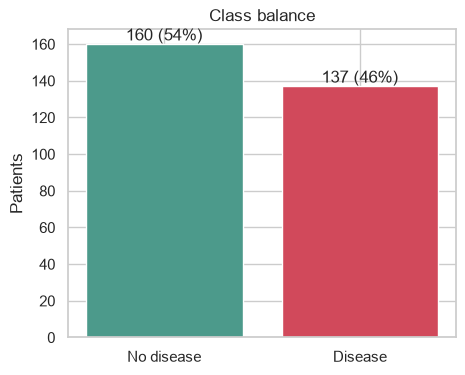

In [5]:
counts = df[TARGET].map(LABELS).value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[0], PALETTE[1]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_title("Class balance")
ax.set_ylabel("Patients")
save(fig, "01_class_balance")
plt.show()

The classes are roughly balanced (~54% / 46%), so no resampling is needed; a stratified train/test split is enough.

## 3. Numeric feature distributions by target

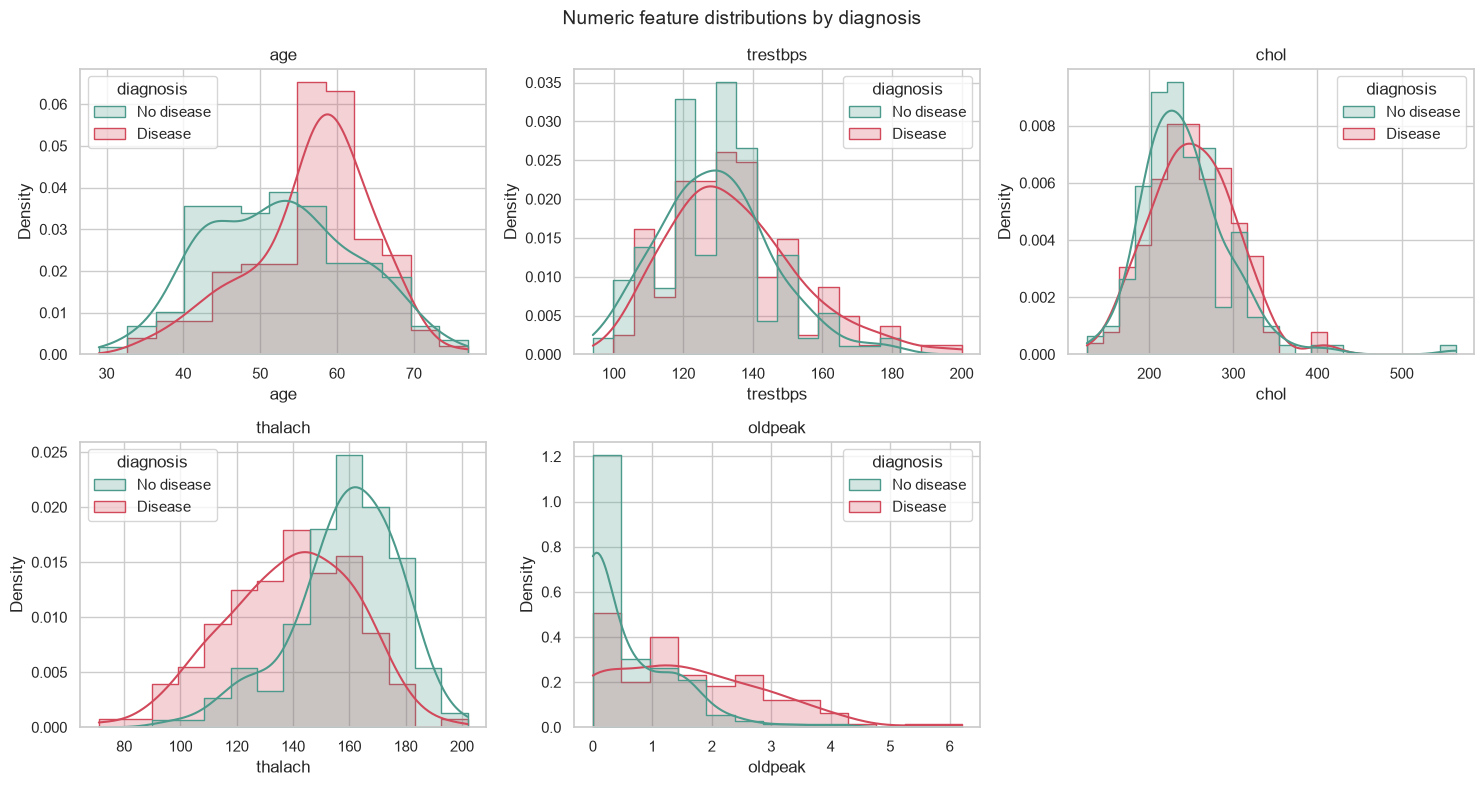

In [6]:
plot_df = df.assign(diagnosis=df[TARGET].map(LABELS))
label_palette = {LABELS[k]: v for k, v in PALETTE.items()}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(data=plot_df, x=col, hue="diagnosis", palette=label_palette,
                 hue_order=[LABELS[0], LABELS[1]], kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
fig.suptitle("Numeric feature distributions by diagnosis", fontsize=14)
fig.tight_layout()
save(fig, "02_numeric_histograms")
plt.show()

Observations: patients with disease tend to have a **lower max heart rate (`thalach`)** and **higher ST depression (`oldpeak`)**, and are slightly older. `chol` and `trestbps` separate the classes only weakly.

## 4. Correlation heatmap

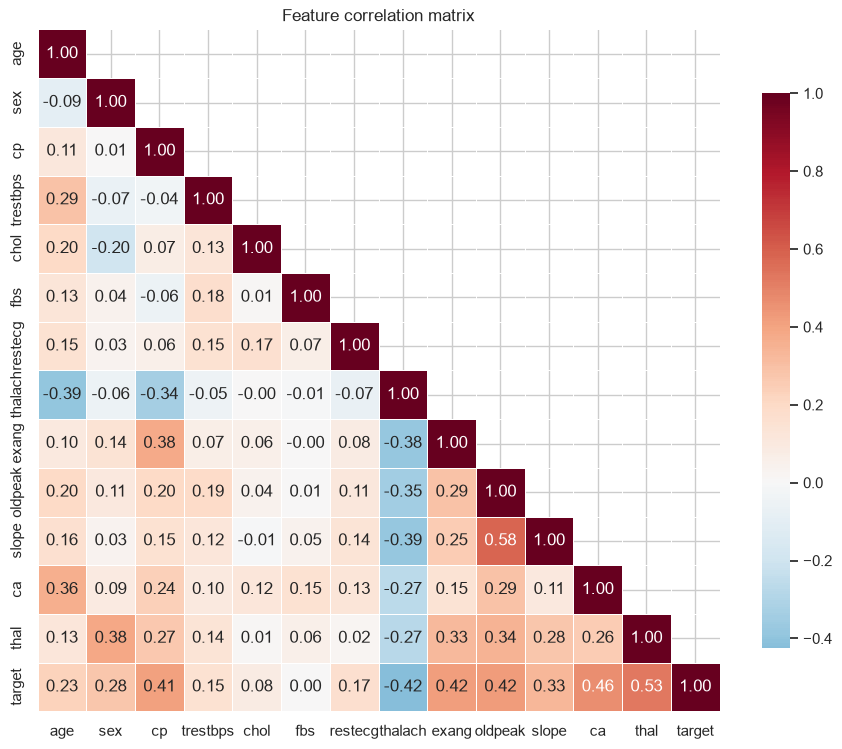

In [7]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Feature correlation matrix")
save(fig, "03_correlation_heatmap")
plt.show()

In [8]:
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

thal        0.527
ca          0.463
oldpeak     0.424
thalach    -0.424
exang       0.421
cp          0.409
slope       0.333
sex         0.278
age         0.227
restecg     0.166
trestbps    0.153
chol        0.080
fbs         0.003
Name: target, dtype: float64

## 5. Disease rate by categorical feature

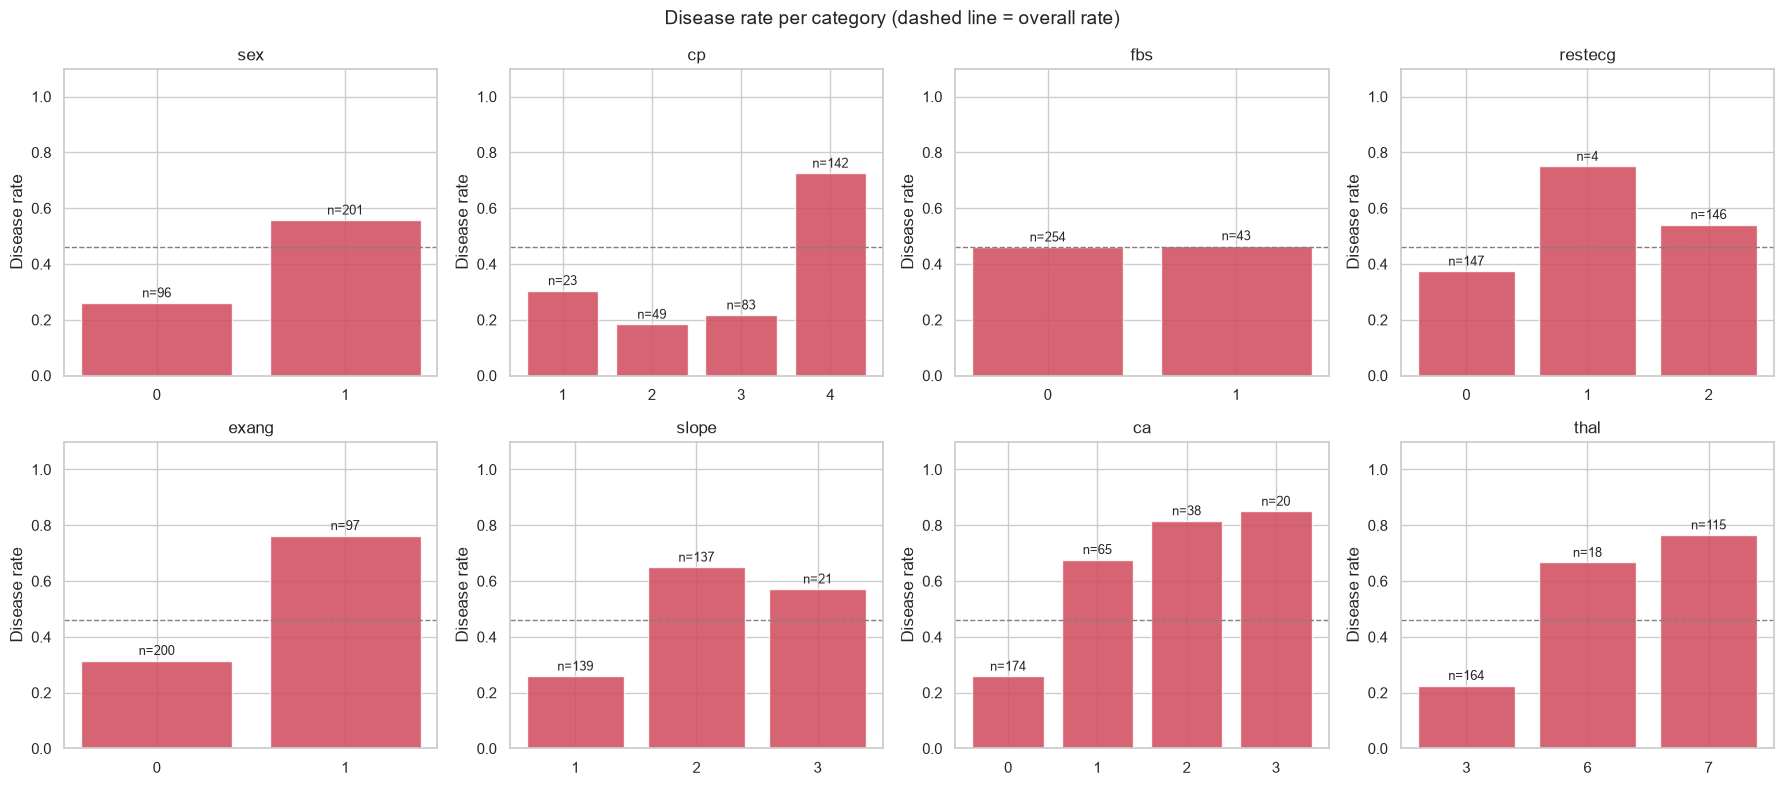

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
overall = df[TARGET].mean()
for ax, col in zip(axes.flat, CATEGORICAL_FEATURES):
    rate = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(rate.index.astype(str), rate["mean"], color="#D1495B", alpha=0.85)
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, m + 0.02, f"n={n}", ha="center", fontsize=9)
    ax.axhline(overall, ls="--", color="grey", lw=1)
    ax.set_ylim(0, 1.1)
    ax.set_title(col)
    ax.set_ylabel("Disease rate")
fig.suptitle("Disease rate per category (dashed line = overall rate)", fontsize=14)
fig.tight_layout()
save(fig, "04_categorical_disease_rate")
plt.show()

Strong categorical signals: asymptomatic chest pain (`cp=4`), exercise-induced angina (`exang=1`), reversible defect (`thal=7`), more coloured vessels (`ca`>0) and male sex all show clearly higher disease rates.

## 6. Outlier check

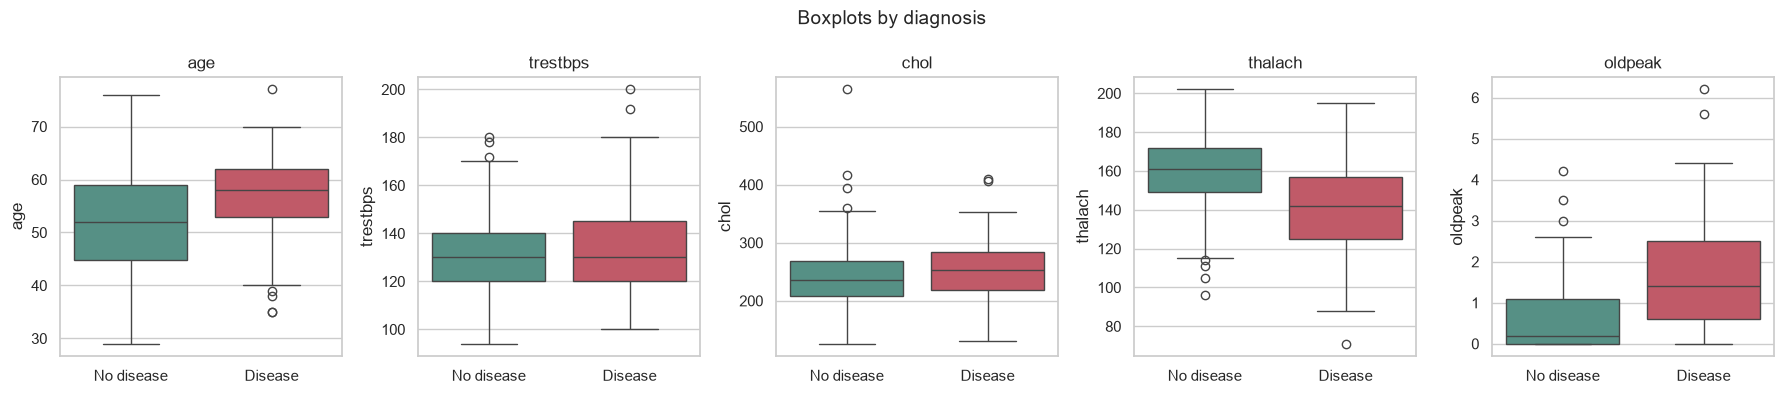

In [10]:
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False, ax=ax)
    ax.set_xticks([0, 1], [LABELS[0], LABELS[1]])
    ax.set_xlabel("")
    ax.set_title(col)
fig.suptitle("Boxplots by diagnosis", fontsize=14)
fig.tight_layout()
save(fig, "05_boxplots")
plt.show()

In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c]) for c in NUMERIC_FEATURES}, name="IQR outliers")

age         0
trestbps    9
chol        5
thalach     1
oldpeak     5
Name: IQR outliers, dtype: int64

A handful of outliers exist (e.g. cholesterol > 500 mg/dl, high resting BP). They are clinically plausible values, so they are **kept**; `StandardScaler` plus tree-based models handle them reasonably.

## 7. Age vs maximum heart rate

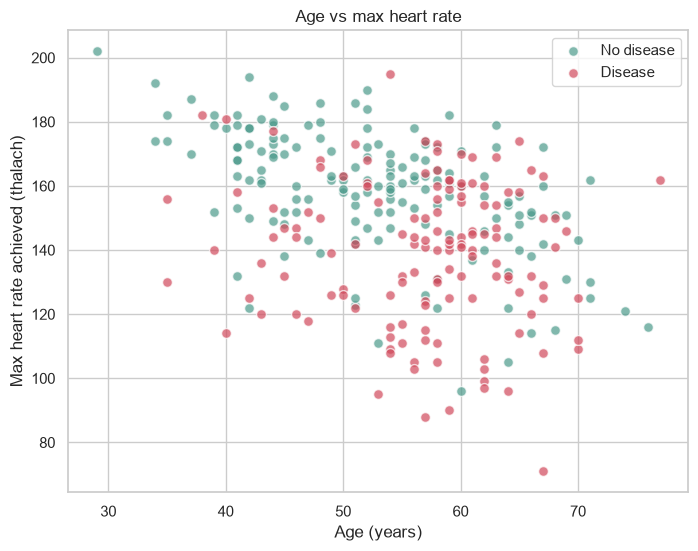

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
for t in (0, 1):
    sub = df[df[TARGET] == t]
    ax.scatter(sub["age"], sub["thalach"], c=PALETTE[t], label=LABELS[t],
               alpha=0.7, edgecolor="white", s=50)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Max heart rate achieved (thalach)")
ax.set_title("Age vs max heart rate")
ax.legend()
save(fig, "06_age_vs_thalach")
plt.show()

## 8. EDA summary

- 297 clean rows, 13 features, balanced binary target (54% / 46%).
- Missing values were rare (6 rows) and dropped.
- Most predictive signals: `thal`, `ca`, `cp`, `exang`, `oldpeak`, `thalach`.
- Categorical codes (`cp`, `thal`, `slope`, `restecg`, `ca`) are nominal → one-hot encode.
- Numeric features have different scales → standardise for linear models.
- Outliers are plausible and kept.